**Eye-Tracking & Neurocognitive Intelligence | Reading Comprehension & Neurocognitive Modelling | Presented by: Reza Saadatyar (2026)**

**05 | Generalisation, Robustness and Final Evaluation**

![Generalisation, Robustness and Final Evaluation — scientific workflow](../../images/05_generalisation_and_final_evaluation.svg)

**Objective:** Reconcile held-out prediction scores, select on Validation, and report matched Test performance and conditional participant uncertainty.

**Dataset:** Fixed trial features, participant assignments and saved scores from Notebooks 03 and 04.

**Scope:** Compare fixed candidates on matched held-out trials, quantify conditional participant uncertainty and examine score calibration without further fitting.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("reading_comprehension_modelling")

# ---------------------------- 2. Standard Library ----------------------------
import sys

# --------------------------- 3. Study Dependencies ---------------------------
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-r",
     str(root / "reading_comprehension_modelling" / "requirements.txt")],
    check=True,
)

# ----------------- 4. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------------ 5. Machine Learning Metrics ------------------------
from sklearn.metrics import confusion_matrix

# ------------------- 6. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

# ----------------- 7. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from onestop_io import validate_splits, validate_trial_index
from reading_evaluation import evaluate, participant_bootstrap

# ------------------- 8. Output Directory and Setup Summary -------------------
out_dir = root / "reading_comprehension_modelling" / "output"
out_dir.mkdir(parents=True, exist_ok=True)
plot_style(
    font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5,
    label_weight="normal", tick_size=10, legend_size=10,
    figure_dpi=100, figure_size=(10, 5),
)
print("Study outputs:", out_dir)
print("Python:", sys.version.split()[0])


Repository up to date.
Study outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/reading_comprehension_modelling/output
Python: 3.13.16


**02. Reconcile Matched Held-Out Predictions**

Match every candidate to every required trial, protocol and role. No duplicate model/trial rows or missing coverage are accepted. The primary candidate for each protocol is determined solely by Validation Macro F1, with alphabetical tie-breaking. All other Test results are secondary comparisons.

**Reconciled evaluation:** The corrected execution at `d51ed6c` uses the same committed cohort, participant assignments and 160,018 scores from Notebooks 03–04. All 76 candidate–protocol–role combinations reproduce their saved metrics. The Validation-only winners are TF-IDF fusion in A (0.5582 Macro F1) and TF-IDF text in B (0.5698); the identities are unchanged from the earlier run.

In [3]:
# ================ 02. Reconcile Matched Held-Out Predictions =================

# ------------------- 1. Load and Reconcile Trial Features --------------------
identity = ["trial_id","participant_id","trial_index","article_batch",
            "article_key","paragraph_key","question_key","difficulty_level"]
table = pd.read_csv(out_dir/"02_trial_features.csv",dtype={c:str for c in identity})
index = pd.read_csv(out_dir/"01_trial_index.csv",dtype=str)
index["is_correct"] = index.is_correct.astype(int)
validate_trial_index(index,table)

# ------------------------- 2. Load Participant Roles -------------------------
splits = pd.read_csv(out_dir/"01_participant_splits.csv",dtype=str)
validate_splits(table,splits)

# --------------- 3. Reconcile Scores and Select on Validation ----------------
scores = pd.concat([pd.read_csv(out_dir/"03_classical_predictions.csv"),
                    pd.read_csv(out_dir/"04_neural_predictions.csv")],ignore_index=True)
data, validation, selected, test, people, strata, calibration = evaluate(table,splits,scores)
display(selected[["protocol","model","macro_f1","n_people","n_trials"]])


,protocol,model,macro_f1,n_people,n_trials
0,B_unseen_batch,tfidf_text,0.569842,24,1295
1,A_unseen_people,tfidf_fusion,0.558242,36,1943


**03. Compare Test Performance and Generalisation**

Report Macro F1 as primary, with balanced accuracy, accuracy, AUROC, incorrect-response precision/recall and AUPRC. Protocol A tests new people within represented batches; Protocol B changes participants and articles together. Their Test cohorts are different, so a performance difference is not an isolated effect of novel text.

**Selected-model Test results:** In A, TF-IDF fusion achieves Macro F1 0.5560, balanced accuracy 0.6161, AUROC 0.6573, incorrect-class precision 0.2813 and recall 0.6058 (1,944 trials, 36 people). In B, TF-IDF text achieves 0.5035, 0.5116, 0.5386, 0.2032 and 0.3058 respectively (3,240 trials, 60 people). The B TF-IDF fusion candidate has the highest secondary Test Macro F1 (0.5296), but is not substituted for the Validation-selected text model. The prevalence reference achieves 0.4462 and 0.4473 Macro F1 with zero incorrect recall. These findings indicate modest discrimination, especially under the harder B protocol.

,protocol,model,n_people,n_trials,accuracy,macro_f1,balanced_accuracy,auroc,incorrect_auprc,incorrect_precision,incorrect_recall,brier
12,A_unseen_people,tfidf_fusion,36,1944,0.622428,0.555986,0.616128,0.657262,0.300205,0.281327,0.605820,0.227171
4,A_unseen_people,forest_text,36,1944,0.619342,0.548071,0.601168,0.640333,0.278454,0.272040,0.571429,0.219270
13,A_unseen_people,tfidf_text,36,1944,0.610597,0.545234,0.604771,0.654344,0.293508,0.271411,0.595238,0.225522
18,A_unseen_people,xgb_text,36,1944,0.565329,0.518373,0.597747,0.627657,0.294445,0.256517,0.650794,0.235385
10,A_unseen_people,mlp_text,36,1944,0.609053,0.518247,0.548623,0.570147,0.259325,0.235457,0.449735,0.242702
16,A_unseen_people,xgb_fusion,36,1944,0.587449,0.513480,0.557289,0.586242,0.270807,0.237624,0.507937,0.238020
0,A_unseen_people,cnn_fusion,36,1944,0.570988,0.500561,0.545065,0.578198,0.263432,0.227273,0.502646,0.244241
5,A_unseen_people,gru_fusion,36,1944,0.574074,0.498182,0.536946,0.572520,0.256523,0.222222,0.476190,0.243709
14,A_unseen_people,transformer_fusion,36,1944,0.567901,0.497420,0.541142,0.574632,0.277909,0.224344,0.497354,0.244390
15,A_unseen_people,transformer_gaze,36,1944,0.680556,0.491676,0.491653,0.520324,0.211044,0.181102,0.182540,0.245468


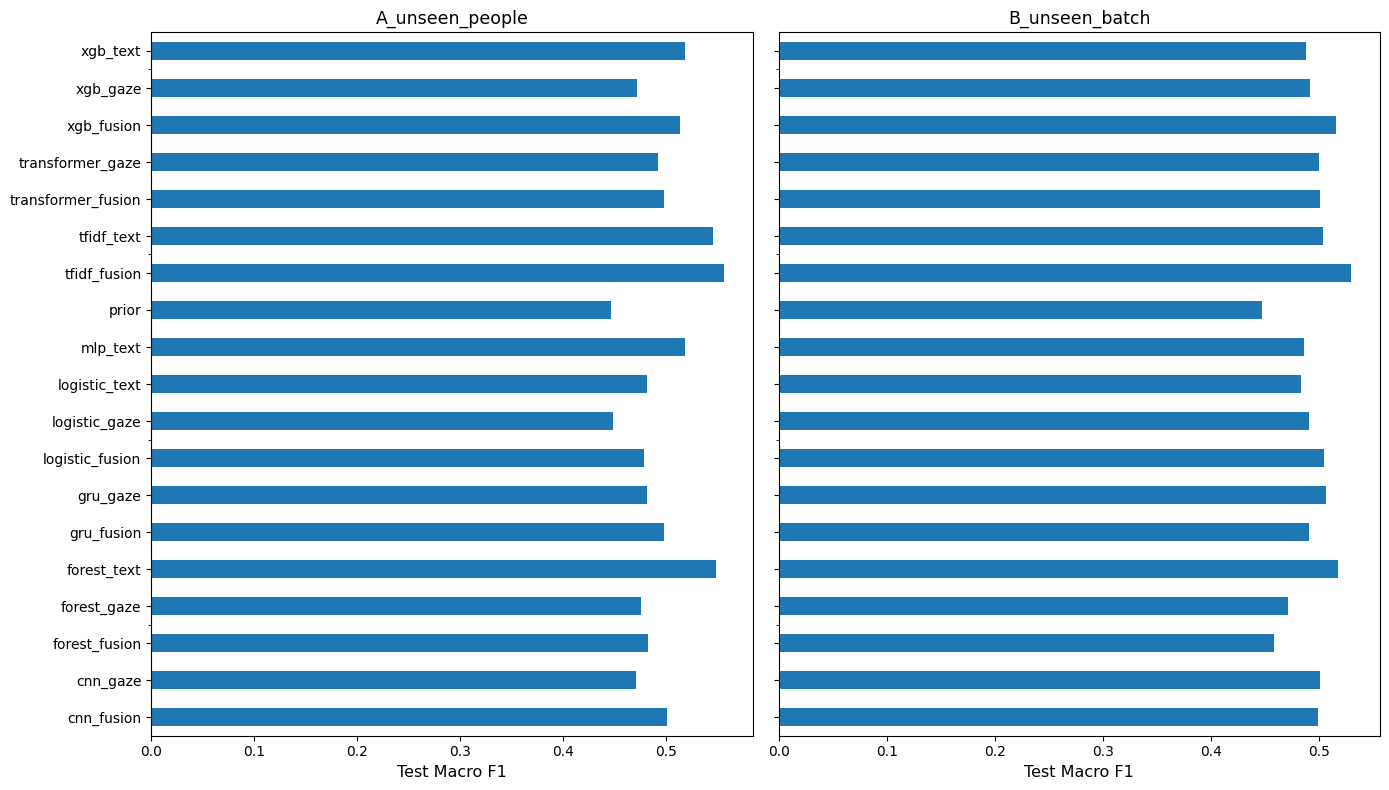

In [4]:
# ============== 03. Compare Test Performance and Generalisation ==============

# ----------------------- 1. Summarise Held-Out Metrics -----------------------
display(test.sort_values(["protocol","macro_f1"],ascending=[True,False]))

# ------------------------ 2. Plot Held-Out Comparison ------------------------
fig, axes = plt.subplots(1,2,figsize=(14,8),sharey=True)
for ax,(protocol,g) in zip(axes,test.groupby("protocol")):
    g.sort_values("model").plot.barh(x="model",y="macro_f1",ax=ax,legend=False)
    ax.set(title=protocol,xlabel="Test Macro F1",ylabel="")
fig.tight_layout()
save_figure(fig,out_dir/"05_test_comparison.png")
plt.show()


**04. Analyse Participant Variation and Difficulty**

Report held-out participant metrics and difficulty-specific results. Single-class participant subsets have undefined AUROC and balanced accuracy; they remain missing rather than being replaced with zero. Difficulty strata are observational.

**Observed variation:** The selected-model participant Macro F1 ranges from 0.3448 to 0.6842 (median 0.5261) in A and 0.3721 to 0.7146 (median 0.4893) in B. Advanced/elementary pooled Macro F1 is 0.5606/0.5489 in A and 0.4904/0.4996 in B. The confusion matrices contain 229/149/585/981 and 189/429/741/1881 entries in observed-row, predicted-column order (0 then 1). These descriptive strata are not causal difficulty effects.

,protocol,model,participant_id,n_trials,accuracy,macro_f1,balanced_accuracy,auroc,incorrect_auprc,incorrect_precision,incorrect_recall,brier
0,A_unseen_people,cnn_fusion,l10_341,54,0.592593,0.541667,0.589286,0.557540,0.326856,0.291667,0.583333,0.246060
1,A_unseen_people,cnn_fusion,l12_207,54,0.555556,0.523529,0.539474,0.539474,0.304752,0.333333,0.500000,0.250134
2,A_unseen_people,cnn_fusion,l12_92,54,0.574074,0.457879,0.491848,0.478261,0.194120,0.142857,0.375000,0.246126
3,A_unseen_people,cnn_fusion,l17_98,54,0.592593,0.410714,0.470588,0.575163,0.082207,0.047619,0.333333,0.243385
4,A_unseen_people,cnn_fusion,l20_253,54,0.722222,0.719820,0.722222,0.695473,0.775168,0.772727,0.629630,0.235238


,protocol,model,difficulty,n_people,n_trials,accuracy,macro_f1,balanced_accuracy,auroc,incorrect_auprc,incorrect_precision,incorrect_recall,brier
0,A_unseen_people,cnn_fusion,Adv,36,972,0.462963,0.444328,0.547758,0.604978,0.305895,0.227806,0.690355,0.254373
1,A_unseen_people,cnn_fusion,Ele,36,972,0.679012,0.526209,0.532231,0.560169,0.216005,0.225941,0.298343,0.234109
2,A_unseen_people,cnn_gaze,Adv,36,972,0.492798,0.426266,0.449108,0.472664,0.204464,0.166667,0.375635,0.250041
3,A_unseen_people,cnn_gaze,Ele,36,972,0.698560,0.497323,0.497374,0.516774,0.211050,0.181818,0.176796,0.247257
4,A_unseen_people,forest_fusion,Adv,36,972,0.793210,0.506266,0.525813,0.580698,0.300431,0.441176,0.076142,0.173955
...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,B_unseen_batch,xgb_fusion,Ele,60,1620,0.688272,0.510082,0.512557,0.526837,0.195056,0.193820,0.240418,0.218702
72,B_unseen_batch,xgb_gaze,Adv,60,1620,0.623457,0.492039,0.496185,0.511899,0.215419,0.200000,0.280967,0.235237
73,B_unseen_batch,xgb_gaze,Ele,60,1620,0.640741,0.490357,0.497346,0.520234,0.185530,0.174393,0.275261,0.232929
74,B_unseen_batch,xgb_text,Adv,60,1620,0.609877,0.499040,0.510105,0.519704,0.207984,0.214421,0.341390,0.240574


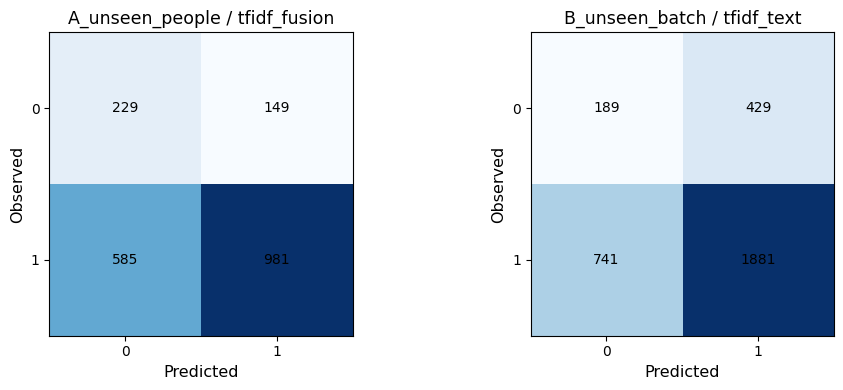

In [5]:
# ============= 04. Analyse Participant Variation and Difficulty ==============

# -------------- 1. Inspect Participant and Difficulty Summaries --------------
display(people.head())
display(strata)

# ----------------- 2. Plot Selected-Model Confusion Matrices -----------------
primary = test.merge(selected[["protocol","model"]],on=["protocol","model"])
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,row in zip(axes,primary.itertuples(index=False)):
    g=data[(data.protocol==row.protocol)&(data.model==row.model)&data.role.eq("test")]
    cm=confusion_matrix(g.is_correct,g.p_correct>=.5,labels=[0,1])
    ax.imshow(cm,cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j,i,str(cm[i,j]),ha="center",va="center")
    ax.set(xticks=[0,1],yticks=[0,1],xlabel="Predicted",ylabel="Observed",
           title=row.protocol+" / "+row.model)
fig.tight_layout()
save_figure(fig,out_dir/"05_selected_confusion.png")
plt.show()


**05. Quantify Paired Participant Uncertainty**

Resample participant confusion counts jointly across candidates (1,000 draws, seed 17). Report conditional percentile intervals for pooled Macro F1 and matched fusion-versus-unimodal differences. Article dependence, retraining and a held-out batch's population variability are not represented.

**Recorded uncertainty:** Selected-model 95% participant percentile intervals for pooled Test Macro F1 are 0.5276–0.5805 (A) and 0.4863–0.5211 (B). TF-IDF fusion minus text is +0.0108 (−0.0127 to +0.0313) in A and +0.0261 (+0.0068 to +0.0432) in B. Logistic and XGBoost fusion also have positive intervals versus text in B, whereas Random Forest fusion has negative intervals versus text in both protocols. These fixed-candidate contrasts are secondary, conditional and not multiplicity-adjusted; they do not justify changing the selected model. The implemented paired intervals cover scalar and lexical families, not neural modality contrasts. All 38 participant and 14 paired intervals were independently reproduced from the committed scores using the specified resampling procedure.

In [6]:
# ================ 05. Quantify Paired Participant Uncertainty ================

# ----------------- 1. Estimate Paired Participant Intervals ------------------
intervals, paired = participant_bootstrap(data,draws=1000,seed=17)
display(intervals)
display(paired)


,protocol,model,n_people,macro_f1_low,macro_f1_high
0,A_unseen_people,cnn_fusion,36,0.480151,0.522849
1,A_unseen_people,cnn_gaze,36,0.448036,0.494733
2,A_unseen_people,forest_fusion,36,0.454292,0.514491
3,A_unseen_people,forest_gaze,36,0.446373,0.510244
4,A_unseen_people,forest_text,36,0.522780,0.573735
5,A_unseen_people,gru_fusion,36,0.478918,0.517882
6,A_unseen_people,gru_gaze,36,0.456481,0.503592
7,A_unseen_people,logistic_fusion,36,0.439401,0.512305
8,A_unseen_people,logistic_gaze,36,0.393178,0.494620
9,A_unseen_people,logistic_text,36,0.461241,0.503007


,protocol,model_a,model_b,difference,difference_low,difference_high
0,A_unseen_people,logistic_fusion,logistic_text,-0.003547,-0.039340,0.029389
1,A_unseen_people,logistic_fusion,logistic_gaze,0.029908,0.005345,0.058481
2,A_unseen_people,forest_fusion,forest_text,-0.065794,-0.107687,-0.025081
3,A_unseen_people,forest_fusion,forest_gaze,0.007190,-0.005895,0.022808
4,A_unseen_people,xgb_fusion,xgb_text,-0.004893,-0.035034,0.023475
5,A_unseen_people,xgb_fusion,xgb_gaze,0.042159,0.024076,0.061342
6,A_unseen_people,tfidf_fusion,tfidf_text,0.010753,-0.012684,0.031321
7,B_unseen_batch,logistic_fusion,logistic_text,0.021266,0.005188,0.036365
8,B_unseen_batch,logistic_fusion,logistic_gaze,0.013245,-0.009159,0.039113
9,B_unseen_batch,forest_fusion,forest_text,-0.059949,-0.083297,-0.037544


**06. Assess Score Calibration**

Compare mean predicted scores and observed correct-response fractions in ten fixed bins. Class weighting and a fixed threshold are used; scores are not claimed to be calibrated probabilities. Brier score is a diagnostic, not evidence of calibration by itself.

**Recorded calibration:** Selected-model Brier scores are 0.2272 and 0.2220, compared with prevalence-reference scores of 0.1567 and 0.1544. Observed correctness exceeds the mean score in most occupied bins (all five in B). The class-weighted outputs should not be interpreted as calibrated probabilities. No post-hoc calibration or threshold optimisation has been applied.

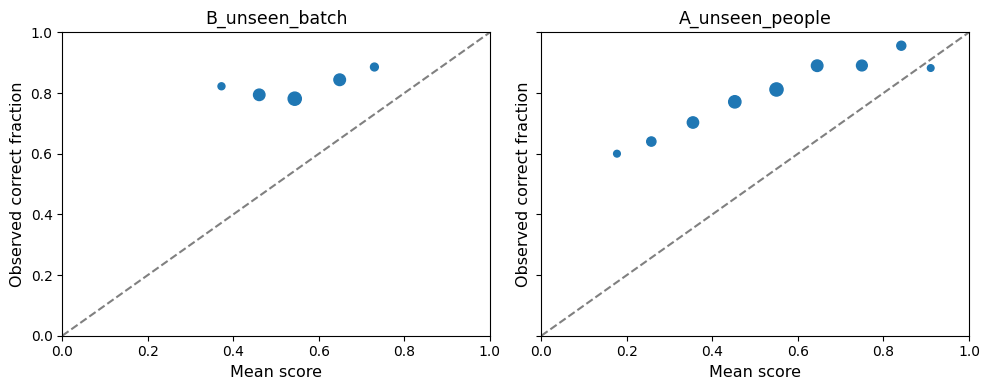

In [7]:
# ======================= 06. Assess Score Calibration ========================

# ------------------------- 1. Plot Score Calibration -------------------------
fig, axes=plt.subplots(1,2,figsize=(10,4),sharey=True)
for ax,row in zip(axes,selected.itertuples(index=False)):
    g=calibration[(calibration.protocol==row.protocol)&(calibration.model==row.model)]
    ax.plot([0,1],[0,1],linestyle="--",color="grey")
    ax.scatter(g.mean_probability,g.observed_fraction,s=20+g.n_trials/g.n_trials.max()*70)
    ax.set(xlim=(0,1),ylim=(0,1),xlabel="Mean score",ylabel="Observed correct fraction",
           title=row.protocol)
fig.tight_layout()
save_figure(fig,out_dir/"05_score_calibration.png")
plt.show()


**07. Save Comparative Evidence and Interpret Scope**

The selected models and secondary comparisons address response correctness for ordinary-reading trials in OneStop. They do not measure general cognitive ability, establish clinical validity or isolate causal gaze effects. The results support limited, model-dependent incremental information from gaze rather than a consistent advantage over text. Ordered neural encoders do not outperform the classical Validation leaders, and the stronger article/participant holdout limits predictive generalisation.

**Current evidence status:** All eleven regenerated outputs are reconciled with the committed producer scores. The previous TF-IDF discrepancy was resolved by rerunning the fixed evaluation in a clean checkout; neither the models nor the partitions or selection rules changed. Test had already been inspected, so this is reconciliation of the same held-out evaluation, not an independent new Test. The saved figures and all metric, participant, difficulty, calibration and bootstrap tables agree with the current predictions. Model refitting, external validation and independent reproduction of the full data pipeline were not performed.

In [8]:
# ============= 07. Save Comparative Evidence and Interpret Scope =============

# --------------------- 1. Save Final Comparative Tables ----------------------
for name,frame in {"05_validation_metrics.csv":validation,"05_selected_models.csv":selected,
                   "05_test_metrics.csv":test,"05_participant_metrics.csv":people,
                   "05_difficulty_metrics.csv":strata,"05_calibration_bins.csv":calibration,
                   "05_participant_intervals.csv":intervals,"05_paired_modality_intervals.csv":paired}.items():
    frame.to_csv(out_dir/name,index=False)

# ------------------------ 2. Package Current Outputs -------------------------
download_outputs_from_colab(out_dir,"05")


------------------------------------------------------------------------
Notebook 05
Files packaged: 11
  + 05_calibration_bins.csv
  + 05_difficulty_metrics.csv
  + 05_paired_modality_intervals.csv
  + 05_participant_intervals.csv
  + 05_participant_metrics.csv
  + 05_score_calibration.png
  + 05_selected_confusion.png
  + 05_selected_models.csv
  + 05_test_comparison.png
  + 05_test_metrics.csv
  + 05_validation_metrics.csv
Download ZIP from Colab Contents: /content/reading_comprehension_modelling_Notebook_05_Outputs.zip
